In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
file_path="C:\\Users\\user\\Downloads\\archive\\EasyVisa.csv"
visa_df=pd.read_csv(file_path)
visa_df.head()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.6500,Year,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,122996.8600,Year,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,83434.0300,Year,Y,Denied
4,EZYV05,Africa,Master's,Y,N,1082,2005,South,149907.3900,Year,Y,Certified


In [16]:
d=dict(visa_df.dtypes)
d

{'case_id': dtype('O'),
 'continent': dtype('O'),
 'education_of_employee': dtype('O'),
 'has_job_experience': dtype('O'),
 'requires_job_training': dtype('O'),
 'no_of_employees': dtype('int64'),
 'yr_of_estab': dtype('int64'),
 'region_of_employment': dtype('O'),
 'prevailing_wage': dtype('float64'),
 'unit_of_wage': dtype('O'),
 'full_time_position': dtype('O'),
 'case_status': dtype('O')}

In [19]:
cat=[]
num=[]
for i in d:
    if d[i]=="O":
        cat.append(i)
    else:
        num.append(i)

In [20]:
cat , num

(['case_id',
  'continent',
  'education_of_employee',
  'has_job_experience',
  'requires_job_training',
  'region_of_employment',
  'unit_of_wage',
  'full_time_position',
  'case_status'],
 ['no_of_employees', 'yr_of_estab', 'prevailing_wage'])

In [21]:
c=visa_df["continent"].unique()


In [28]:
count=[]
for i in c:
    count.append(len(visa_df[visa_df["continent"]==i]))

In [27]:
visa_df["continent"].value_counts()

continent
Asia             16861
Europe            3732
North America     3292
South America      852
Africa             551
Oceania            192
Name: count, dtype: int64

In [29]:
pd.DataFrame(zip(c,count),columns=["continent","count"])

,continent,count
0,Asia,16861
1,Africa,551
2,North America,3292
3,Europe,3732
4,South America,852
5,Oceania,192


In [30]:
d=dict(visa_df["continent"].value_counts())
d

{'Asia': np.int64(16861),
 'Europe': np.int64(3732),
 'North America': np.int64(3292),
 'South America': np.int64(852),
 'Africa': np.int64(551),
 'Oceania': np.int64(192)}

In [38]:
pd.DataFrame(d,index=[1])

,Asia,Europe,North America,South America,Africa,Oceania
1,16861,3732,3292,852,551,192


In [43]:
visa_df["continent"].value_counts().values
visa_df["continent"].value_counts().keys()

Index(['Asia', 'Europe', 'North America', 'South America', 'Africa',
       'Oceania'],
      dtype='object', name='continent')

In [ ]:
IQR=Q3-Q1
ub=Q3+1.5*IQR
lb=Q1-1.5*IQR

In [45]:
q3=np.percentile(visa_df["prevailing_wage"],75)
q1=np.percentile(visa_df["prevailing_wage"],25)
IQR=q3-q1
ub=q3+1.5*IQR
lb=q1-1.5*IQR

In [47]:
ub,lb

(np.float64(218315.56125000003), np.float64(-76564.56875000002))

In [49]:
con1=visa_df["prevailing_wage"]>ub
con2=visa_df["prevailing_wage"]<lb
visa_df[con1|con2]

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
14,EZYV15,Asia,Master's,Y,Y,15756,2006,South,220081.73,Year,Y,Certified
34,EZYV35,Asia,Master's,N,N,1809,2010,South,225569.73,Year,N,Certified
130,EZYV131,South America,High School,N,N,2554,2005,Midwest,247393.01,Year,Y,Certified
216,EZYV217,Asia,Master's,Y,N,1515,2001,Midwest,269321.68,Year,N,Certified
221,EZYV222,North America,Doctorate,Y,Y,2518,2010,South,219529.62,Year,Y,Certified
...,...,...,...,...,...,...,...,...,...,...,...,...
25191,EZYV25192,Asia,Master's,N,N,4983,2005,Midwest,280482.51,Year,Y,Denied
25195,EZYV25196,North America,Master's,Y,N,47,2001,South,234308.77,Year,N,Certified
25468,EZYV25469,Asia,Bachelor's,N,N,373,2005,Midwest,272715.74,Year,N,Certified
25469,EZYV25470,North America,Master's,Y,N,2261,1997,Northeast,273772.47,Year,N,Certified


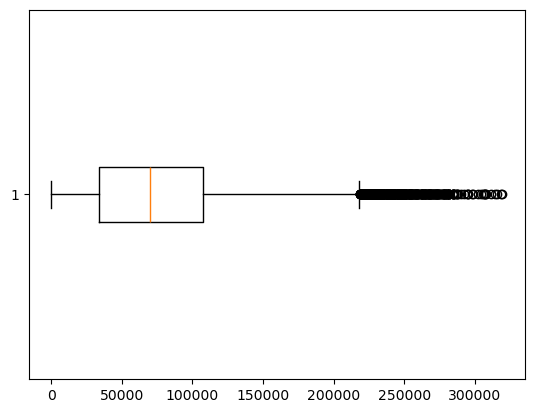

In [56]:
outlier=visa_df[con1|con2]
plt.boxplot(visa_df["prevailing_wage"], vert=False)
plt.show()

In [57]:
visa_df["prevailing_wage"].mean()

np.float64(74455.81459209183)

In [3]:
wine_df=pd.read_csv(r"C:\Users\user\Downloads\datasets\winequality_red.csv")
wine_df

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
...,...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


{'whiskers': [<matplotlib.lines.Line2D at 0x235fe1d0e10>,
 'caps': [<matplotlib.lines.Line2D at 0x235fe1d1090>,
 'boxes': [<matplotlib.lines.Line2D at 0x235fe1d0cd0>],
 'medians': [<matplotlib.lines.Line2D at 0x235fe1d1310>],
 'fliers': [<matplotlib.lines.Line2D at 0x235fe1d1450>],
 'means': []}

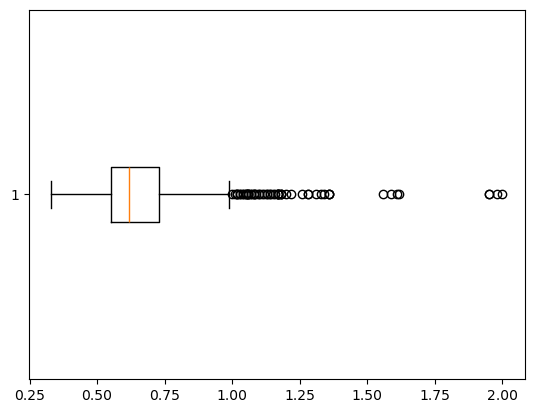

In [9]:
plt.boxplot(wine_df["sulphates"],vert=False)

In [49]:
q1=np.percentile(wine_df["sulphates"],25)
q3=np.percentile(wine_df["sulphates"],75)
IQR=q3-q1
ub=q3+1.5*IQR
lb=q1-1.5*IQR
con1=wine_df["sulphates"]>ub
con2=wine_df["sulphates"]<lb

len(wine_df[["sulphates"]][con1|con2])

59

In [22]:
wine_df["sulphates"].median()

0.62

In [43]:
l=[]
for i in wine_df["sulphates"].values:
    if i>ub or i<lb:
        i=wine_df["sulphates"].median()
        l.append(i)
    else:
        l.append(i)
l


[np.float64(0.56),
 np.float64(0.68),
 np.float64(0.65),
 np.float64(0.58),
 np.float64(0.56),
 np.float64(0.56),
 np.float64(0.46),
 np.float64(0.47),
 np.float64(0.57),
 np.float64(0.8),
 np.float64(0.54),
 np.float64(0.8),
 np.float64(0.52),
 0.62,
 np.float64(0.88),
 np.float64(0.93),
 np.float64(0.75),
 0.62,
 np.float64(0.5),
 0.62,
 np.float64(0.53),
 np.float64(0.65),
 np.float64(0.91),
 np.float64(0.53),
 np.float64(0.63),
 np.float64(0.56),
 np.float64(0.59),
 np.float64(0.91),
 np.float64(0.55),
 np.float64(0.59),
 np.float64(0.54),
 np.float64(0.57),
 np.float64(0.66),
 np.float64(0.52),
 np.float64(0.55),
 np.float64(0.55),
 np.float64(0.6),
 np.float64(0.73),
 np.float64(0.48),
 np.float64(0.83),
 np.float64(0.83),
 np.float64(0.51),
 np.float64(0.9),
 0.62,
 np.float64(0.52),
 np.float64(0.56),
 np.float64(0.73),
 np.float64(0.58),
 np.float64(0.56),
 np.float64(0.58),
 np.float64(0.74),
 np.float64(0.63),
 np.float64(0.64),
 np.float64(0.56),
 np.float64(0.63),
 np.floa

In [44]:
outliers_removed=pd.DataFrame(l,columns=["sulphates"])

{'whiskers': [<matplotlib.lines.Line2D at 0x23582199450>,
 'caps': [<matplotlib.lines.Line2D at 0x235821996d0>,
 'boxes': [<matplotlib.lines.Line2D at 0x23582199310>],
 'medians': [<matplotlib.lines.Line2D at 0x23582199950>],
 'fliers': [<matplotlib.lines.Line2D at 0x23582199a90>],
 'means': []}

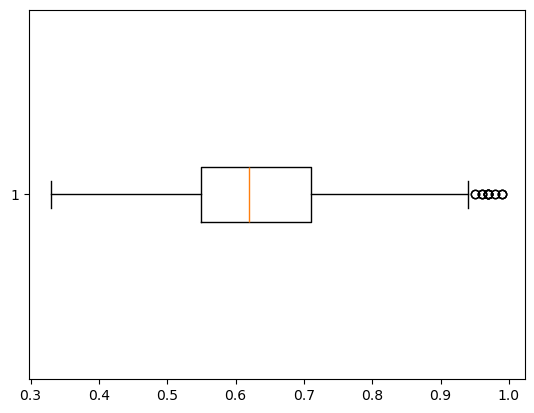

In [48]:
plt.boxplot(outliers_removed,vert=False)